# Confidence ablation

This notebook reads one completed development experiment
It creates tables and figures for the project report

Run the controller from the repository root with the Python environment used by the project

```powershell
python -m src.scripts.run_ablation --device 0
```

Inspect the planned conditions before inference with the dry run option

```powershell
python -m src.scripts.run_ablation --device 0 --dry-run
```

Continue a compatible saved experiment with the resume option

```powershell
python -m src.scripts.run_ablation --device 0 --resume
```

Open this notebook after the controller finishes
Set ABLATION_DIR below or use the environment variable with the same name
The default directory is outputs/ablation/confidence_dev

All conditions use the same development videos and counting rules
Confidence is the factor that changes
The tracker thresholds stay fixed at their recorded values
At confidence 0.1 the tracker can use observations below its high threshold of 0.25
At confidence 0.25 and higher those observations are filtered before tracking


Frame times include detector and tracker calls
Image loading and report generation are outside this timing
Each condition contributes one recorded timing pass

The same seed is used for every condition
The manifest records software versions and input fingerprints
If a tracking condition stops before completion move that condition folder aside before resuming
A lock file left after a system crash can be removed after its process has stopped


In [1]:
import json
import os
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the repository so the notebook works from the root or the scripts folder
ROOT = next((directory for directory in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (directory / "src").is_dir() and (directory / "reports").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook from the repository or its scripts folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.provenance import file_info, write_json
from src.eval.counting_metrics import mae, wape, mean_sce

# Change this directory when comparing another saved experiment
ABLATION_DIR = Path(os.environ.get("ABLATION_DIR", "outputs/ablation/confidence_dev"))
if not ABLATION_DIR.is_absolute():
    ABLATION_DIR = ROOT / ABLATION_DIR
ABLATION_DIR = ABLATION_DIR.resolve()
manifest_path = ABLATION_DIR / "manifest.json"
OUTPUT_DIR = ABLATION_DIR / "analysis"
CLASSES = ["car", "bus", "truck", "all"]
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.size": 10, "font.family": "sans-serif"})
print(f"Experiment directory: {ABLATION_DIR}")

Experiment directory: C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\debug\VehicleDetectionAndTrafficCounting\outputs\ablation\confidence_dev


# Read and check the saved experiment

The manifest lists the conditions and the output files of every stage
A complete manifest and matching file fingerprints are required before plotting
This prevents a partial experiment from appearing as a full comparison

MAE is the average absolute counting error across videos
WAPE divides the sum of absolute counting errors by the total GT count
SCE is the predicted count minus the GT count
A missing WAPE means that the total GT count for that class is zero

In [2]:
def read_json(path):
    """Read one report and give a useful error if it is missing"""
    if not path.is_file():
        raise FileNotFoundError(f"Missing experiment file: {path}")
    return json.loads(path.read_text(encoding="utf-8"))


def experiment_path(relative):
    """Resolve an output path inside the selected experiment"""
    result = (ABLATION_DIR / relative).resolve()
    if not result.is_relative_to(ABLATION_DIR):
        raise ValueError("A manifest output path points outside the experiment")
    return result


def check_number(actual, expected, name):
    """Check a saved counting metric against its original count vectors"""
    if actual is None and expected is None:
        return
    if actual is None or expected is None or not np.isclose(actual, expected):
        raise ValueError(f"Counting metric differs from its source values: {name}")


manifest = read_json(manifest_path)
if manifest.get("version") != 1 or manifest.get("status") != "complete":
    raise ValueError("Finish or resume the experiment before running this notebook")
plan = manifest["plan"]
if plan["split"] != "dev":
    raise ValueError("This notebook expects a development confidence experiment")
sequences = plan["sequences"]
confidences = plan["confidences"]
jobs = plan["jobs"]
# Require every confidence to contain the same two detectors and two trackers
# Missing conditions would make the comparison incomplete
expected_grid = {(confidence, model, tracker) for confidence in confidences
                 for model in ("yolov8n.pt", "yolov8s.pt") for tracker in ("bytetrack", "botsort")}
actual_grid = [(job["confidence"], job["model"], job["tracker"]) for job in jobs]
if len(actual_grid) != len(expected_grid) or set(actual_grid) != expected_grid:
    raise ValueError("The experiment does not contain the expected confidence grid")
expected_stages = {"gt_counts", "gt_mot"}
expected_stages.update("tracks/" + job["config"] for job in jobs)
for confidence in confidences:
    expected_stages.update(f"{stage}/{confidence:g}" for stage in ("counts", "counting", "tracking"))
if set(manifest["stages"]) != expected_stages:
    raise ValueError("The experiment manifest has missing or unexpected stages")
# Check the actual saved bytes before reading metrics from any report
# The experiment can be moved because these output paths are relative
for name, stage in manifest["stages"].items():
    if stage["status"] != "complete" or not stage["outputs"]:
        raise ValueError(f"The stage is incomplete: {name}")
    for record in stage["outputs"]:
        source = experiment_path(record["path"])
        if file_info(source)["sha256"] != record["sha256"]:
            raise ValueError(f"An experiment output changed: {source}")
print(f"Validated {len(jobs)} conditions on {len(sequences)} development videos")
print(f"Confidence values: {confidences}")
print(f"Counting observation gap: {plan['max_frame_gap']}")
print(f"Recorded tracking environment: {manifest['tracking_environment']}")

Validated 16 conditions on 5 development videos
Confidence values: [0.1, 0.25, 0.4, 0.6]
Counting observation gap: 1
Recorded tracking environment: {'device': 'NVIDIA GeForce RTX 4060', 'torch': '2.14.1+cu126', 'ultralytics': '8.4.175', 'opencv': '5.0.0', 'python': '3.12.5', 'cuda': '12.6', 'numpy': '2.4.4', 'cudnn': 91002}


# Build the report tables

The main table has one row for each confidence and configuration
Per class and per video tables help explain the overall error
Tracking percentages use the combined TrackEval statistics across videos
Latency includes the detector and tracker and excludes image reading and video writing


MAE and WAPE rank conditions in the same order on this fixed split
Their denominators are constant across the sweep
Per class GT totals show when a class has only a small number of vehicles


In [3]:
# Keep one table for the main curves and two tables for closer inspection
# The detailed tables help explain class errors and differences between videos
summary_rows, class_rows, sequence_rows = [], [], []
gt_path = experiment_path("shared/gt_counts.json")
gt_counts = read_json(gt_path)["dev"]
# Read the reports for each confidence without repeating inference
for confidence in confidences:
    selected = [job for job in jobs if job["confidence"] == confidence]
    reports_dir = experiment_path(selected[0]["reports"])
    counting = read_json(reports_dir / "counting_eval_dev.json")
    tracking = read_json(reports_dir / "tracking_eval_dev.json")
    predicted_path = reports_dir / "track_counts.json"
    predictions = read_json(predicted_path)["dev"]
    expected_configs = {job["config"] for job in selected}
    if set(tracking) != expected_configs or {key for key in counting if not key.startswith("_")} != expected_configs:
        raise ValueError("Report configurations differ from the experiment plan")
    if counting["_gt"]["variant"] != "exclude_ignored":
        raise ValueError("Unexpected counting GT variant")
    for key, source in (("gt", gt_path), ("tracks", predicted_path)):
        if counting["_sources"][key]["sha256"] != file_info(source)["sha256"]:
            raise ValueError(f"Counting source differs: {source}")
    for job in selected:
        config = job["config"]
        timing_path = experiment_path(job["tracks"]) / "dev" / config / "timing.json"
        timing = read_json(timing_path)
        if timing["conf"] != confidence or timing["split"] != "dev" or timing["imgsz"] != plan["imgsz"]:
            raise ValueError(f"Tracking settings differ for {config}")
        tracking_body = tracking[config]
        if tracking_body["sources"]["timing"]["sha256"] != file_info(timing_path)["sha256"]:
            raise ValueError(f"Tracking report refers to another run for {config}")
        # Dataset metrics are already combined by TrackEval in the evaluation script
        # Using these saved values keeps aggregation consistent across conditions
        combined = tracking_body["aggregate"]["combined"]
        tracker_label = {"bytetrack": "ByteTrack", "botsort": "BoT-SORT"}[job["tracker"]]
        approach = f"{Path(job['model']).stem.replace('yolov8', 'YOLOv8')} + {tracker_label}"
        for class_name in CLASSES:
            result = counting[config][class_name]
            gt = [gt_counts[sequence]["exclude_ignored"][class_name]["total"] for sequence in sequences]
            predicted = [predictions[config][sequence]["counts"][class_name]["total"] for sequence in sequences]
            if result["gt"] != gt or result["pred"] != predicted or result["sce"] != (np.asarray(predicted) - gt).tolist():
                raise ValueError(f"Count vectors differ for {config} and {class_name}")
            # Recalculate counting metrics from the saved predicted and GT counts
            # This also checks that the sequence order matches the fixed split
            for metric, expected in (("mae", mae(predicted, gt)), ("wape", wape(predicted, gt)),
                                     ("mean_sce", mean_sce(predicted, gt))):
                check_number(result[metric], expected, metric)
            # Store WAPE as a percentage for readable tables and graph labels
            row = {"Approach": approach, "Config": config, "Confidence": confidence,
                   "Class": class_name, "GT total": sum(gt), "Pred total": sum(predicted),
                   "MAE": result["mae"], "WAPE (%)": None if result["wape"] is None else 100 * result["wape"],
                   "Mean SCE": result["mean_sce"]}
            class_rows.append(row)
            for sequence, target, prediction in zip(sequences, gt, predicted):
                sequence_rows.append({"Approach": approach, "Config": config, "Confidence": confidence,
                                      "Class": class_name, "Sequence": sequence, "GT": target,
                                      "Pred": prediction, "SCE": prediction - target,
                                      "Absolute error": abs(prediction - target)})
            if class_name == "all":
                summary_rows.append({**row, "HOTA (%)": combined["HOTA"], "MOTA (%)": combined["MOTA"],
                                     "IDF1 (%)": combined["IDF1"],
                                     "IDSW": tracking_body["aggregate"]["sum"]["IDSW"],
                                     "Detector ms": timing["det_ms_per_frame"],
                                     "Tracker ms": timing["trk_ms_per_frame"],
                                     "Latency ms": timing["total_ms_per_frame"], "FPS": timing["fps"]})
summary = pd.DataFrame(summary_rows)
per_class = pd.DataFrame(class_rows)
per_sequence = pd.DataFrame(sequence_rows)
report_table = summary[["Confidence", "Approach", "MAE", "WAPE (%)", "IDF1 (%)", "Latency ms"]].copy()
print(report_table.round(3).to_markdown(index=False))

|   Confidence | Approach            |   MAE |   WAPE (%) |   IDF1 (%) |   Latency ms |
|-------------:|:--------------------|------:|-----------:|-----------:|-------------:|
|         0.1  | YOLOv8n + ByteTrack |   6.4 |     12.749 |     74.798 |        9.007 |
|         0.1  | YOLOv8n + BoT-SORT  |   6.8 |     13.546 |     78.427 |       13.204 |
|         0.1  | YOLOv8s + ByteTrack |   4.2 |      8.367 |     78.79  |       10.701 |
|         0.1  | YOLOv8s + BoT-SORT  |   4.2 |      8.367 |     81.414 |       15.231 |
|         0.25 | YOLOv8n + ByteTrack |   8   |     15.936 |     75.652 |        7.136 |
|         0.25 | YOLOv8n + BoT-SORT  |   8   |     15.936 |     77.483 |       15.99  |
|         0.25 | YOLOv8s + ByteTrack |   4.2 |      8.367 |     79.379 |       12.703 |
|         0.25 | YOLOv8s + BoT-SORT  |   4.2 |      8.367 |     82.501 |       16.515 |
|         0.4  | YOLOv8n + ByteTrack |  11.2 |     22.311 |     76.032 |        7.698 |
|         0.4  | YOLOv8n + BoT-S

# Compare confidence curves

Compare confidence values within each curve to study one pipeline
Compare curves at the same confidence to study detector and tracker choices
The zero line in the SCE plot separates overcounts and undercounts
Use the per video table to check whether one busy video explains a large change

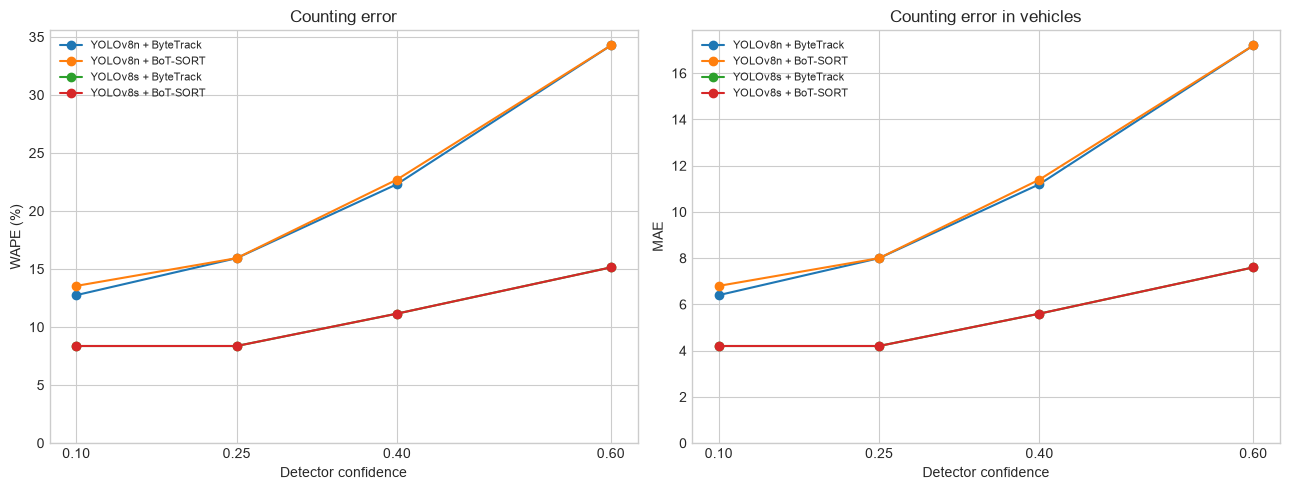

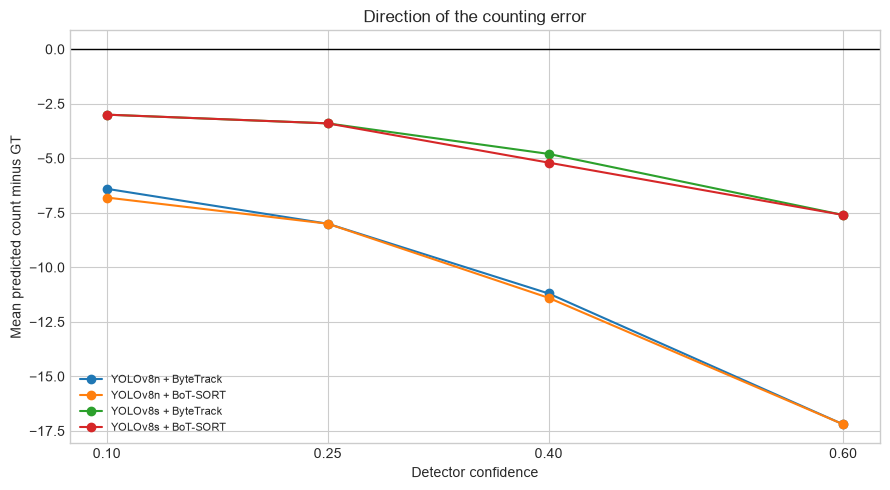

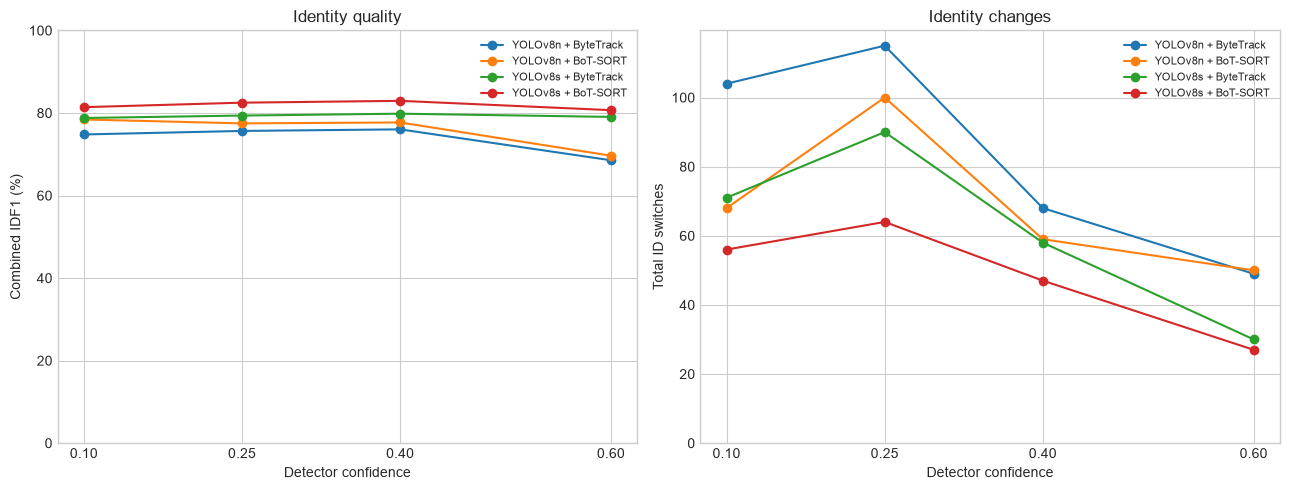

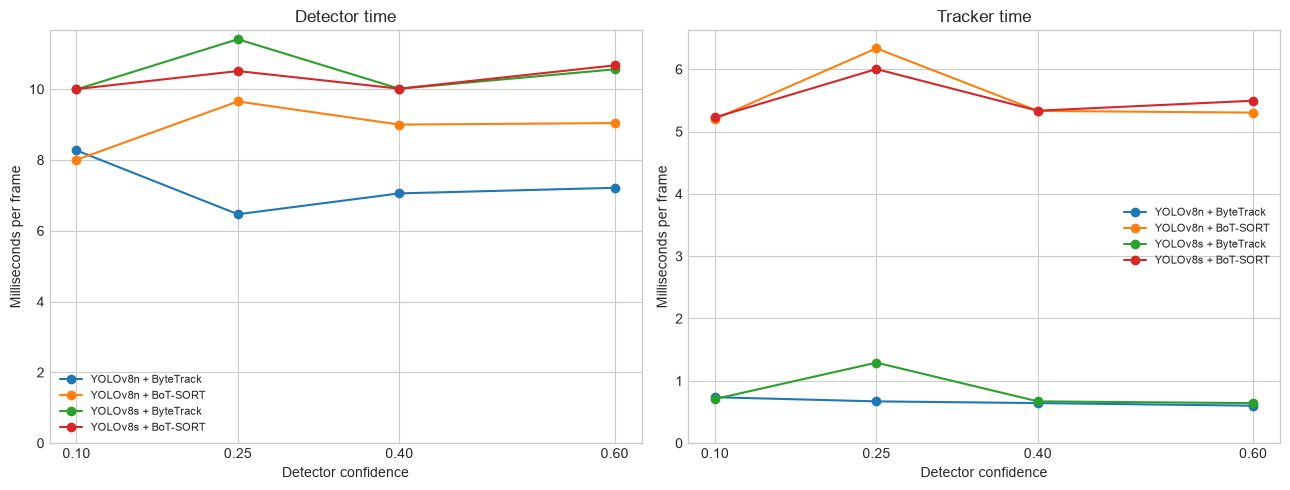

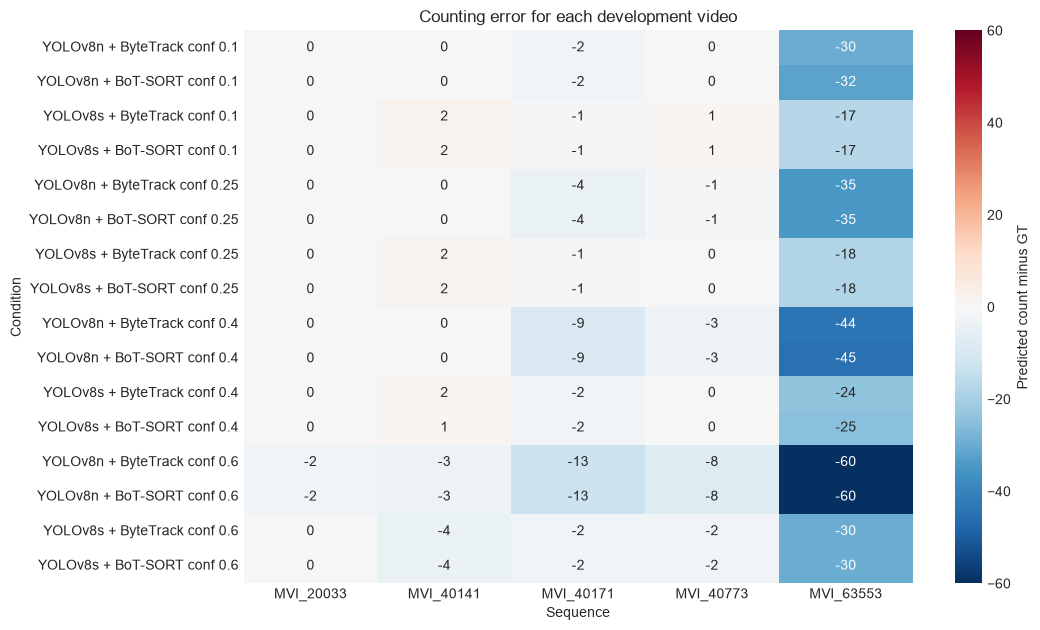

In [4]:
CHARTS_DIR, TABLES_DIR = OUTPUT_DIR / "charts", OUTPUT_DIR / "tables"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
generated_files = []


def plot_curves(axis, column, title, ylabel, zero=False):
    """Draw one curve for each detector and tracker pair in a stable order"""
    for approach, part in summary.groupby("Approach", sort=False):
        part = part.sort_values("Confidence")
        axis.plot(part["Confidence"], part[column], marker="o", label=approach)
    axis.set(title=title, xlabel="Detector confidence", ylabel=ylabel, xticks=confidences)
    if zero:
        axis.axhline(0, color="black", linewidth=1)
    axis.legend(fontsize=8)


def save_figure(figure, name):
    """Save the same figure as a raster image and a vector PDF for the report"""
    figure.tight_layout()
    for extension in ("png", "pdf"):
        target = CHARTS_DIR / f"{name}_dev.{extension}"
        figure.savefig(target, dpi=200, bbox_inches="tight")
        generated_files.append(target)
    if plt.get_backend().lower() != "agg":
        plt.show()
    plt.close(figure)


figure, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_curves(axes[0], "WAPE (%)", "Counting error", "WAPE (%)")
plot_curves(axes[1], "MAE", "Counting error in vehicles", "MAE")
for axis in axes:
    axis.set_ylim(bottom=0)
save_figure(figure, "counting_sensitivity")

figure, axis = plt.subplots(figsize=(9, 5))
plot_curves(axis, "Mean SCE", "Direction of the counting error", "Mean predicted count minus GT", zero=True)
save_figure(figure, "signed_counting_error")

figure, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_curves(axes[0], "IDF1 (%)", "Identity quality", "Combined IDF1 (%)")
plot_curves(axes[1], "IDSW", "Identity changes", "Total ID switches")
axes[0].set_ylim(0, 100)
axes[1].set_ylim(bottom=0)
save_figure(figure, "tracking_sensitivity")

figure, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_curves(axes[0], "Detector ms", "Detector time", "Milliseconds per frame")
plot_curves(axes[1], "Tracker ms", "Tracker time", "Milliseconds per frame")
for axis in axes:
    axis.set_ylim(bottom=0)
save_figure(figure, "latency_sensitivity")

# Keep the fixed video order so errors can be traced back to the split
all_counts = per_sequence[per_sequence["Class"] == "all"].copy()
all_counts["Condition"] = all_counts["Approach"] + " conf " + all_counts["Confidence"].map(lambda value: f"{value:g}")
error_grid = all_counts.pivot(index="Condition", columns="Sequence", values="SCE")
error_grid = error_grid.reindex(index=all_counts["Condition"].drop_duplicates(), columns=sequences)
limit = max(1, float(np.abs(error_grid.to_numpy()).max()))
figure, axis = plt.subplots(figsize=(11, max(4, 0.4 * len(error_grid))))
sns.heatmap(error_grid, annot=True, fmt=".0f", cmap="RdBu_r", center=0,
            vmin=-limit, vmax=limit, ax=axis, cbar_kws={"label": "Predicted count minus GT"})
axis.set_title("Counting error for each development video")
save_figure(figure, "sequence_errors")

# Export and interpret the results

CSV tables keep the original numeric precision
Markdown and LaTeX tables use three decimal places for report formatting
Undefined values are shown as n/a

Use these questions when writing the interpretation

Does a lower confidence help every video or only some videos
Do better identity metrics also improve the counting error
Does the detector or tracker change the shape of the confidence curve
Does a lower total counting error hide a class error

The notebook displays the measured conditions
The final confidence choice should follow the selection rule agreed by the team

In [5]:
# Save the complete data before rounding values for the report
# Rounded text tables are intended for reading rather than further calculations
for name, table in (("ablation_summary", summary), ("ablation_report", report_table),
                    ("ablation_per_class", per_class),
                    ("ablation_per_sequence", per_sequence)):
    csv_path = TABLES_DIR / f"{name}_dev.csv"
    table.to_csv(csv_path, index=False)
    generated_files.append(csv_path)
    formatted = table.copy().astype(object)
    for column in table.columns:
        if pd.api.types.is_integer_dtype(table[column]):
            formatted[column] = table[column].map(str)
        elif pd.api.types.is_numeric_dtype(table[column]):
            formatted[column] = table[column].map(lambda value: "n/a" if pd.isna(value) else f"{value:.3f}")
    for extension, content in (("md", formatted.to_markdown(index=False, disable_numparse=True)),
                               ("tex", formatted.to_latex(index=False, escape=True))):
        target = TABLES_DIR / f"{name}_dev.{extension}"
        target.write_text(content + "\n", encoding="utf-8")
        generated_files.append(target)

# Save the source manifest fingerprint next to the exported report materials
analysis_manifest = {"experiment_manifest": file_info(manifest_path), "tracking_aggregation": "combined",
                     "notebook": file_info(ROOT / "scripts/ablation.ipynb"),
                     "outputs": [file_info(target) for target in generated_files]}
write_json(OUTPUT_DIR / "analysis_manifest.json", analysis_manifest)
print(f"Saved {len(generated_files)} tables and figures to {OUTPUT_DIR}")

Saved 22 tables and figures to C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\debug\VehicleDetectionAndTrafficCounting\outputs\ablation\confidence_dev\analysis
